<h1>Goals of these projects</h1>
<p>I want to make a model to predict LA LIGA stats. SHOTS,SHOTS ON TARGET, CARDS, GOALS</p>

In [25]:
import sqlite3
import numpy as np
import pandas as pd

In [26]:
query = """
SELECT t.match_id, tm.name AS team, op.name AS opponent,
       s.name AS season, m.kickoff_utc, m.round_no,
       CASE WHEN t.team_id = m.home_team_id THEN 1 ELSE 0 END AS is_home,
       CASE WHEN t.team_id = m.home_team_id THEN m.home_score ELSE m.away_score END AS goals_for,
       CASE WHEN t.team_id = m.home_team_id THEN m.away_score ELSE m.home_score END AS goals_against,
       t.passes_own_half + t.passes_opp_half AS passes
FROM team_match_stats t
JOIN matches m  ON m.match_id  = t.match_id
JOIN seasons s  ON s.season_id = m.season_id
JOIN teams tm   ON tm.team_id  = t.team_id
JOIN teams op   ON op.team_id  = CASE WHEN t.team_id = m.home_team_id THEN m.away_team_id ELSE m.home_team_id END
WHERE s.competition_id = 1 AND t.period = 'ALL'
"""
df = pd.read_sql_query(query, conn)
df["kickoff_utc"] = pd.to_datetime(df["kickoff_utc"])
df = df.sort_values("kickoff_utc").reset_index(drop=True)


In [27]:
g = df.groupby("team")["passes"]
for k in range(1, 6):
    df[f"passes_lag{k}"] = g.shift(k)

In [28]:
X = pd.get_dummies(df, columns=["team", "opponent"])

In [29]:
df["pts"] = np.select([df["goals_for"] > df["goals_against"],
                       df["goals_for"] == df["goals_against"]], [3, 1], 0)
df["pts_before"] = df.groupby(["team", "season"])["pts"].cumsum() - df["pts"]

opp = df[["match_id", "team", "pts_before"]].rename(columns={"team": "opponent", "pts_before": "opp_pts_before"})
df = df.merge(opp, on=["match_id", "opponent"])
df["pts_diff"] = df["pts_before"] - df["opp_pts_before"]

In [30]:
df.columns

Index(['match_id', 'team', 'opponent', 'season', 'kickoff_utc', 'round_no',
       'is_home', 'goals_for', 'goals_against', 'passes', 'passes_lag1',
       'passes_lag2', 'passes_lag3', 'passes_lag4', 'passes_lag5', 'pts',
       'pts_before', 'opp_pts_before', 'pts_diff'],
      dtype='object')

In [31]:
nan_counts = df.isna().sum()
nan_table = pd.DataFrame({
    "nan_count": nan_counts,
    "nan_pct": (nan_counts / len(df) * 100).round(1)
}).sort_values("nan_count", ascending=False)

nan_table

,nan_count,nan_pct
passes_lag5,125,5.5
passes_lag4,100,4.4
passes_lag3,75,3.3
passes_lag2,50,2.2
passes_lag1,25,1.1
match_id,0,0.0
team,0,0.0
opponent,0,0.0
season,0,0.0
round_no,0,0.0


In [ ]:
print(len(df))
df = df.dropna()
print(len(df))

2280


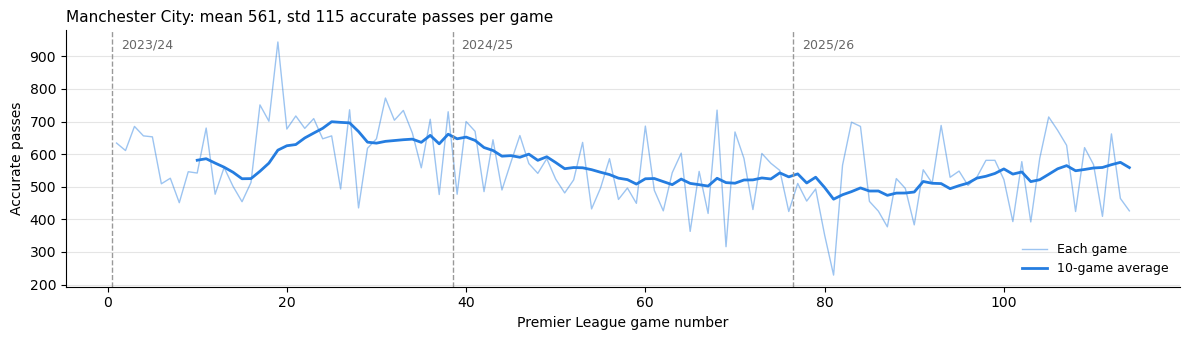

In [36]:
import matplotlib.pyplot as plt

plot_query = """
SELECT tm.name AS team, s.name AS season, m.kickoff_utc,
       t.passes_own_half + t.passes_opp_half AS passes
FROM team_match_stats t
JOIN matches m ON m.match_id  = t.match_id
JOIN seasons s ON s.season_id = m.season_id
JOIN teams tm  ON tm.team_id  = t.team_id
WHERE s.competition_id = 1 AND t.period = 'ALL'
ORDER BY m.kickoff_utc
"""
plot_df = pd.read_sql_query(plot_query, conn)
plot_df["kickoff_utc"] = pd.to_datetime(plot_df["kickoff_utc"])

teams = ["Manchester City"]        # add more, e.g. ["Manchester United", "Manchester City", "Burnley"]
colors = ["#257de0", "#f47230", "#00b894", "#6a4ce2"]

fig, axes = plt.subplots(len(teams), 1, figsize=(12, 3.5 * len(teams)), sharey=True, squeeze=False)

for ax, team, color in zip(axes[:, 0], teams, colors):
    d = plot_df[plot_df["team"] == team].reset_index(drop=True)
    game = d.index + 1

    ax.plot(game, d["passes"], color=color, linewidth=1, alpha=0.45, label="Each game")
    ax.plot(game, d["passes"].rolling(10).mean(), color=color, linewidth=2, label="10-game average")

    # dashed line where each season starts
    for start in d.index[d["season"] != d["season"].shift()]:
        ax.axvline(start + 0.5, color="#999999", linewidth=1, linestyle="--")
        ax.text(start + 1.5, 0.97, d.loc[start, "season"], transform=ax.get_xaxis_transform(),
                va="top", fontsize=9, color="#666666")

    ax.set_title(f"{team}: mean {d['passes'].mean():.0f}, std {d['passes'].std():.0f} accurate passes per game",
                 loc="left", fontsize=11)
    ax.set_ylabel("Accurate passes")
    ax.grid(axis="y", color="#e5e5e5", linewidth=0.8)
    ax.spines[["top", "right"]].set_visible(False)
    ax.legend(loc="lower right", frameon=False, fontsize=9)

axes[-1, 0].set_xlabel("Premier League game number")
plt.tight_layout()
plt.show()
